# Stochastic Analysis of NANOGrav 15-year dataset with per-pulsar time spans

This notebook analyzes the NANOGrav 15-year dataset under the same model as `gwb_pe.ipynb` (power law intrinsic red noise in every pulsar with 30 frequency bins, and a power law GWB with Hellings-Downs correlations and 14 frequency bins), with one change: the intrinsic red noise of each pulsar lives on a Fourier basis with the harmonics of **that pulsar's own observing span** $T_\text{psr}$,

$$f_k = k / T_\text{psr}, \qquad k = 1, \dots, 30,$$

rather than the span $T$ of the whole PTA. This is Enterprise's default for per-pulsar Gaussian processes (`FourierBasisGP(..., Tspan=None)`). The GWB stays on the PTA span, since its inter-pulsar correlations relate Fourier coefficients at the *same* frequency in every pulsar.

### Requirements

- This notebook should be executed on a (NVIDIA) GPU with CUDA-enabled JAX.

- The analysis requires the packages imported in the following cell, and other common packages.

- Single precision (`float32`) is used throughout, except for one matrix factorization in double precision (`float64`); see the README.

In [1]:
# import os
# os.environ['CUDA_VISIBLE_DEVICES'] = '1'

# to load/save objects
import json
import pickle
from la_forge import core
from enterprise_extensions.load_feathers import load_feathers_from_folder

# for plotting
import numpy as np
import matplotlib.pyplot as plt
import corner
from iris import Iris

# for sampling
import jax
import jax.numpy as jnp
import jax.random as jr
import numpyro

# prometheus objects
from prometheus import data
from prometheus.data import FourierBasis
from prometheus.spectral_models import IndependentSpectralModel, CommonSpectralModel
from prometheus import spectra
from prometheus.pta_model import PTAModel
from prometheus import utilities as utils

%load_ext autoreload
%autoreload 2

libstempo not installed. PINT or libstempo are required to use par and tim files.


In [2]:
# check that we are running on a GPU
# this should print something like "CudaDevice(id=...)"
print(jax.devices())

[CudaDevice(id=0), CudaDevice(id=1)]


## Load Data

**Prometheus** stores PTA data in a custom `prometheus.data.Data` object. This object may be constructed from a list of `enterprise.Pulsar.PintPulsar` (or `FeatherPulsar`) objects and a white noise dictionary.

The `Data` object needs only be constructed once per dataset, after which it can be stored and used repeatedly under different models. The exception is when we wish to change the Fourier bases (their number of frequency bins or time spans), or the number of frequency bins in the deterministic signal model.

First we'll load the pulsar objects and white noise dictionary (obtained from the [NANOGrav 15-year stochastic analysis GitHub repository](https://github.com/nanograv/15yr_stochastic_analysis/tree/main/tutorials/data)).

In [3]:
# load feather pulsar objects
psrs = load_feathers_from_folder('../data/NG15/feathers')

# load white noise dictionary
with open('../data/NG15/15yr_wn_dict.json', 'r') as fp:
    wn_dict = json.load(fp)

# optional: load dictionary of pulsar distances
# used in CW analysis
with open('../data/NG15/pulsar_distances_15yr.pkl', 'rb') as fp:
    psr_dists_dict = pickle.load(fp)

FeatherPulsar.read_feather: cannot find fitpars in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J1312+0051.feather.
FeatherPulsar.read_feather: cannot find setpars in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J1312+0051.feather.
FeatherPulsar.read_feather: cannot find _pdist in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J1312+0051.feather.
FeatherPulsar.read_feather: cannot find fitpars in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J0613-0200.feather.
FeatherPulsar.read_feather: cannot find setpars in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J0613-0200.feather.
FeatherPulsar.read_feather: cannot find _pdist in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J0613-0200.feather.
FeatherPulsar.read_feather: cannot find fitpars in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J0610-2100.feather.
FeatherPulsar.read_feather: cannot find setpars in feather file ../data/NG15/feathers

### Fourier bases

Gaussian processes live on named Fourier bases of the `Data` object (see the README). We need two:

- `'red'`: the achromatic basis on the PTA span, built with `nfreqs` bins. Here it holds **only the GWB**, so we give it the 14 bins of the GWB model. (In the sampling model used below, every bin of a basis in use enters the per-pulsar linear algebra, so bins the GWB does not use would only cost time.)
- `'rn'`: an achromatic basis with 30 bins for the intrinsic red noise. `Tspan='psr'` gives each pulsar the harmonics $k / T_\text{psr}$ of its own span, $T_\text{psr} = \max(t) - \min(t)$ over its TOAs.

The noise-weighted inner products of these bases (with each other, the deterministic basis, and the residuals) are computed once per pulsar, when the `Data` object is built.

In [4]:
# now we can construct the prometheus.data.Data object
# 'red': PTA span, 14 bins (GWB); 'rn': each pulsar's own span, 30 bins (intrinsic red noise)
NG15_data = data.Data(name='NG15_psr_Tspan',
                      psrs=psrs,
                      wn_dict=wn_dict,
                      nfreqs=30,
                      psr_dists_dict=psr_dists_dict,
                      extra_bases=[FourierBasis('rn', nfreqs=30, Tspan='psr')])
print(type(NG15_data))

building pulsar models:   0%|          | 0/67 [00:00<?, ?it/s, running J1312+0051]

building pulsar models: 100%|██████████| 67/67 [01:00<00:00,  1.11it/s, running J0437-4715]


<class 'prometheus.data.Data'>


In [ ]:
# save the data object for future analyses
NG15_data.save_data(filepath='../data/NG15/data_psr_Tspan.pkl')

# # or load a previously constructed data object
# with open('../data/NG15/data_psr_Tspan.pkl', 'rb') as fp:
#     NG15_data = pickle.load(fp)

In [5]:
# the data object contains useful attributes
print(f'number of pulsars in array = {NG15_data.npsrs}')
print(f'total observation span [s] = {NG15_data.Tspan}')
print(f'Fourier bases = {NG15_data.basis_names}')
print(f'red noise basis = {NG15_data.get_basis("rn")}')

# the red noise basis has different frequencies in every pulsar: shape (npsrs, nfreqs)
print(f'red noise frequencies: shape {NG15_data.basis_freqs("rn").shape}, '
      f'GWB frequencies: shape {NG15_data.basis_freqs("red").shape}')

number of pulsars in array = 67
total observation span [s] = 505861299.1401644
Fourier bases = ['red', 'rn']
red noise basis = FourierBasis('rn', nfreqs=30, chromatic_index=0, fref=1400, Tspan='psr')
red noise frequencies: shape (67, 30), GWB frequencies: shape (30,)


## Construct Spectral Models

As in `gwb_pe.ipynb`, we use two spectral models:

1) `prometheus.spectral_models.IndependentSpectralModel` for the intrinsic pulsar noise:
- The same spectral model (here a power law) is applied independently to every pulsar in the array.
- We put it on the `'rn'` basis. The `get_phi_diag_func` is then evaluated on each pulsar's own frequencies $k / T_\text{psr}$; `spectra.power_law` takes the frequency bin width from the frequencies it is given, so each pulsar's prior covariance uses $\Delta f = 1 / T_\text{psr}$, as in Enterprise.

2) `prometheus.spectral_models.CommonSpectralModel` for the GWB:
- A common power law spectrum is applied to all pulsars under Hellings-Downs correlations.
- It lives on the `'red'` basis (the default), on the PTA span. A common process cannot live on a basis with `Tspan='psr'`, whose frequencies differ between pulsars.

In [7]:
# we'll model the pulsar noise with a power law
# the IndependentSpectralModel automatically applies this model to
# every pulsar in the array independently, each on its own frequencies
psr_model = IndependentSpectralModel(name='psr_params',
                                     get_phi_diag_func=spectra.free_spectral,
                                     parameter_bounds=[[-20., -6.]] * NG15_data.nfreqs,
                                     data=NG15_data,
                                     basis='rn')

# model the GWB with a power law and HD correlations
# on the 14 frequency bins of the 'red' basis (PTA span)
gwb_model = CommonSpectralModel(name='gwb_params',
                                get_phi_diag_func=spectra.free_spectral,
                                parameter_bounds=[[-20., -6]] * NG15_data.nfreqs,
                                correlation_matrix='HD',
                                data=NG15_data,
                                nfreqs=30)

## Build a PTA Model

Now we put everything together in a `prometheus.pta_model.PTAModel` object.

In `gwb_pe.ipynb`, the intrinsic noise and the GWB share the `'red'` basis, so the `PTAModel` describes both with one set of Fourier coefficients and samples all of them (the `'shared'` sampling model). Here the two processes live on different bases, so the `PTAModel` uses its `'marginalized'` sampling model (`PTAModel.sampling_model_marginalized`): the intrinsic noise coefficients are marginalized analytically, pulsar by pulsar, and only the GWB Fourier coefficients ($N_\text{psr} \times 2 \times 14$ of them) are sampled, through a standardizing transform conditional on the marginalized intrinsic noise.

The per-pulsar linear algebra acts on the stacked basis $[F_\text{GWB} \,|\, F_\text{rn}]$. Since the GWB frequencies $k / T$ are no longer among the red noise frequencies $k / T_\text{psr}$, this basis is larger than the single shared basis of `gwb_pe.ipynb`, but the number of *sampled* parameters is not.

In [8]:
# plug pulsar noise and GWB model into the PTA model
pta_model = PTAModel(psr_model=psr_model,
                     gwb_model=gwb_model)
print(type(pta_model))
print(f'sampling model: {pta_model.sampling}')
print(f'stacked bases: {list(pta_model.stacked_bases())}')

<class 'prometheus.pta_model.PTAModel'>
sampling model: marginalized
stacked bases: ['red', 'rn']


## Sample the posterior!

The `PTAModel` builds a NumPyro probabilistic sampling model. We'll use NumPyro's No U-Turn Sampler (NUTS), an extension of Hamiltonian Monte Carlo (HMC) to sample the posterior. For an introduction to HMC sampling, see e.g. [this paper](https://arxiv.org/abs/1701.02434).

__WARNING__: On occasion, the NUTS sampler will warm-up in a non-representative region of parameter space, which causes poor sampling. You can identify this failure by examining the step-size after running for 100 HMC steps or so. If the step-size falls below $\sim 10^{-5}$, terminate the run and try again - this time with a different random seed.

In [9]:
# build the NumPyro NUTS kernel
nuts_kernel = numpyro.infer.NUTS(model=pta_model.sampling_model)

# specify MCMC attributes
mcmc = numpyro.infer.MCMC(sampler=nuts_kernel,
                          num_warmup=1000,
                          num_samples=5000)

# seed to start sampling
# (see "WARNING" above: change if necessary)
seed = 170817

# sample!
mcmc.run(jr.PRNGKey(seed), extra_fields=('diverging',))
samples = mcmc.get_samples()

sample: 100%|██████████| 6000/6000 [22:31<00:00,  4.44it/s, 63 steps of size 4.96e-02. acc. prob=0.87]    


In [1]:
# uncomment to examine more sampling diagnostics
# (this is a long output because we sample
# ALL the GWB Fourier coefficients)

# mcmc.print_summary()

In [14]:
# save samples to feather file
utils.save_chain(samples_dict=samples,
                 filepath='chains/NG15_GwbHdFs30_RnFs30_psrTspan.feather',
                 save_coeff_samples=False)

# we can also load samples
# samples = utils.load_chain('chains/NG15_HD_PL_Nf14_psr_Tspan.feather')

Saved chain samples to chains/NG15_GwbHdFs30_RnFs30_psrTspan.feather.


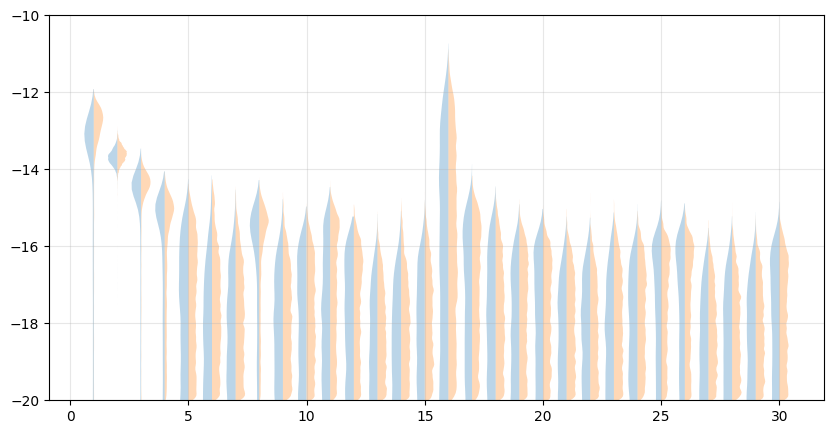

In [16]:
pta_tspan = utils.load_chain('../../NG15_redux/new_analyses/chains/GwbHdFs30_RnFs30.feather')
plt.figure(figsize=(10, 5))
plt.violinplot(np.array(pta_tspan['gwb_params']), showextrema=False, widths=0.8, side='low', bw_method=0.05)
plt.violinplot(np.array(samples['gwb_params']), showextrema=False, widths=0.8, side='high', bw_method=0.05)
plt.ylim(-20, -10)
plt.grid(alpha=0.3)
plt.show()